# CSE 4101 – Practical Lab Assignment 09
## Complete Machine Learning Workflow for Bike Rental Demand Forecasting

**Goal:** predict daily bike rental demand (`cnt`) from calendar and weather information using a **time-aware regression** workflow:
collect → explore → chronological split → train-only preprocessing → train models → tune on the later validation block → final test on the latest block → forecast & interpret.

**How to run (Google Colab):** *Runtime → Run all*. No configuration is needed – the notebook finds `day.csv`
(local `data/` folder → download from the project's GitHub repository → manual upload prompt as the last fallback).

| Section | Assignment task |
|---|---|
| 0 | Setup, seeds, data loading |
| 1 | Task 1 – Inspect the daily file |
| 2 | Task 2 – Exploratory analysis & visualisations |
| 3 | Task 3 – Leakage identification |
| 4 | Task 4 – Chronological 70/15/15 split |
| 5 | Task 5 – Train-only preprocessing |
| 6 | Task 6 – Dummy / Linear / Random Forest |
| 7 | Task 7 – Hyper-parameter tuning on validation block |
| 8 | Task 8 – Train vs validation diagnostics |
| 9 | Task 9 – Final test evaluation (MAE, RMSE) |
| 10 | Task 10 – Five-day forecast, seasonal change, conclusion |

## 0. Setup, reproducibility and data loading

In [1]:
import os, json, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42                       # single global random seed (documented key decision)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

FIG_DIR, RES_DIR = "results/figures", "results"
os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png"); plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| seaborn", sns.__version__)
print("Random seed:", SEED)

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | seaborn 0.13.2
Random seed: 42


In [2]:
# Locate day.csv: local copy -> GitHub download -> manual upload (Colab)
RAW_URL = "https://raw.githubusercontent.com/ahsanulhoqueabir/bike-rental-demand-forecasting/main/data/day.csv"
DATA_PATH = next((p for p in ["data/day.csv", "day.csv", "/content/day.csv"] if os.path.exists(p)), None)
if DATA_PATH is None:
    try:
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(RAW_URL, "data/day.csv"); DATA_PATH = "data/day.csv"
        print("Downloaded day.csv from the project repository.")
    except Exception as e:
        print("Download failed:", e, "\nPlease upload day.csv (Kaggle: yasserh/bike-sharing-dataset).")
        from google.colab import files
        up = files.upload(); DATA_PATH = list(up.keys())[0]
print("Using:", DATA_PATH)

Using: data/day.csv


## 1. Task 1 – Find and inspect the daily observations file

The Kaggle archive contains a single daily file, `day.csv` (730 rows). We inspect its structure, data types,
date range and count ranges, and compare the **actual** field names with the names given in the assignment.

In [3]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape); print(); df.info(); print(); display(df.head())

Shape: (730, 16)

<class 'pandas.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     730 non-null    int64  
 1   dteday      730 non-null    str    
 2   season      730 non-null    int64  
 3   yr          730 non-null    int64  
 4   mnth        730 non-null    int64  
 5   holiday     730 non-null    int64  
 6   weekday     730 non-null    int64  
 7   workingday  730 non-null    int64  
 8   weathersit  730 non-null    int64  
 9   temp        730 non-null    float64
 10  atemp       730 non-null    float64
 11  hum         730 non-null    float64
 12  windspeed   730 non-null    float64
 13  casual      730 non-null    int64  
 14  registered  730 non-null    int64  
 15  cnt         730 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.4 KB



,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,6,0,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,0,0,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,1,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,2,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,3,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600


In [4]:
# The date column is dd-mm-yyyy text -> parse with an explicit format (avoids day/month ambiguity)
df["dteday"] = pd.to_datetime(df["dteday"], format="%d-%m-%Y")

print("Date range      :", df.dteday.min().date(), "->", df.dteday.max().date())
print("Already sorted  :", df.dteday.is_monotonic_increasing)
print("Duplicate dates :", df.dteday.duplicated().sum(), "| duplicate rows:", df.duplicated().sum())
print("Day gaps        :", df.dteday.diff().dropna().value_counts().to_dict())
print("Rows per year   :", df.dteday.dt.year.value_counts().sort_index().to_dict())
print()
print("cnt range       :", df.cnt.min(), "->", df.cnt.max(), "| mean %.1f | median %.1f" % (df.cnt.mean(), df.cnt.median()))
print("  lowest day    :", df.loc[df.cnt.idxmin(), "dteday"].date(), "| highest day:", df.loc[df.cnt.idxmax(), "dteday"].date())
print("casual range    :", df.casual.min(), "->", df.casual.max(), "| registered range:", df.registered.min(), "->", df.registered.max())

schema = pd.DataFrame({
    "Assignment name": ["season","year","month","holiday","weekday","workingday","weather","temperature","humidity","windspeed","cnt"],
    "Actual column":   ["season","yr","mnth","holiday","weekday","workingday","weathersit","temp (+ atemp)","hum","windspeed","cnt"],
    "Type / coding":   ["int 1-4","int 0/1 (0=2018, 1=2019)","int 1-12","int 0/1","int 0-6","int 0/1","int 1-3 (no level 4 present)",
                        "float, deg C (already de-normalised)","float, % (0-100)","float, already de-normalised","int target"]})
print("\nField-name differences (documented):"); display(schema)
print("Extra columns not in the assignment list: instant (row index), dteday (date), atemp (feels-like temp), casual, registered")

Date range      : 2018-01-01 -> 2019-12-31
Already sorted  : True
Duplicate dates : 0 | duplicate rows: 0
Day gaps        : {Timedelta('1 days 00:00:00'): 729}
Rows per year   : {2018: 365, 2019: 365}

cnt range       : 22 -> 8714 | mean 4508.0 | median 4548.5
  lowest day    : 2019-10-29 | highest day: 2019-09-15
casual range    : 2 -> 3410 | registered range: 20 -> 6946

Field-name differences (documented):


,Assignment name,Actual column,Type / coding
0,season,season,int 1-4
1,year,yr,"int 0/1 (0=2018, 1=2019)"
2,month,mnth,int 1-12
3,holiday,holiday,int 0/1
4,weekday,weekday,int 0-6
5,workingday,workingday,int 0/1
6,weather,weathersit,int 1-3 (no level 4 present)
7,temperature,temp (+ atemp),"float, deg C (already de-normalised)"
8,humidity,hum,"float, % (0-100)"
9,windspeed,windspeed,"float, already de-normalised"


Extra columns not in the assignment list: instant (row index), dteday (date), atemp (feels-like temp), casual, registered


### Observations (Task 1)
* **Dataset differs from the textbook UCI version:** the file covers **1 Jan 2018 – 31 Dec 2019** (730 consecutive days, no gaps, no duplicates), not 2011–2012, and dates are `dd-mm-yyyy` text, so they were parsed with an explicit format.
* **Field names differ** from the assignment (`yr`, `mnth`, `weathersit`, `temp`, `hum`; plus extra `instant`, `atemp`). `temp`, `hum`, `windspeed` are already in real units (°C, %, …), so no de-normalising is needed, and `weathersit` only takes values 1–3.
* **Count range:** `cnt` runs from **22** (29 Oct 2019, an extreme low) to **8,714** (15 Sep 2019), mean ≈ 4,508 – demand is large and varies by a factor of almost 400, so errors should be judged in absolute terms (MAE/RMSE) rather than percentages.

## 2. Task 2 – Exploratory data analysis

We report descriptive statistics, missing values, the target distribution, and create labelled visualisations of demand over time,
by season, and by weather category. Category codes are mapped to readable labels (see the note on season coding below).

In [5]:
SEASON_LBL  = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
WEATHER_LBL = {1: "Clear / Few clouds", 2: "Mist / Cloudy", 3: "Light snow / Light rain"}
eda = df.copy()
eda["season_lbl"]  = eda.season.map(SEASON_LBL)
eda["weather_lbl"] = eda.weathersit.map(WEATHER_LBL)

# season codes in THIS file follow astronomical seasons (code 1 = Dec 21-Mar 20) - verify rather than assume
print("Months covered by each season code:")
display(pd.crosstab(eda.season_lbl, eda.dteday.dt.month_name().str[:3]).reindex(columns=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]))
print("Mean temperature by season code (deg C):", eda.groupby("season_lbl").temp.mean().round(1).to_dict())

Months covered by each season code:


dteday,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
season_lbl,,,,,,,,,,,,
Fall,0,0,0,0,0,0,0,0,16,62,60,40
Spring,0,0,22,60,62,40,0,0,0,0,0,0
Summer,0,0,0,0,0,20,62,62,44,0,0,0
Winter,62,56,40,0,0,0,0,0,0,0,0,22


Mean temperature by season code (deg C): {'Fall': 17.3, 'Spring': 22.3, 'Summer': 29.0, 'Winter': 12.2}


In [6]:
print("Descriptive statistics:"); display(df.drop(columns=["instant"]).describe().T.round(2))
print("Missing values per column:"); display(df.isna().sum().to_frame("missing").T)
print("Total missing:", int(df.isna().sum().sum()))
print("\nTarget (cnt): skew = %.3f, excess kurtosis = %.3f" % (df.cnt.skew(), df.cnt.kurt()))

Descriptive statistics:


,count,mean,min,25%,50%,75%,max,std
dteday,730,2018-12-31 12:00:00,2018-01-01 00:00:00,2018-07-02 06:00:00,2018-12-31 12:00:00,2019-07-01 18:00:00,2019-12-31 00:00:00,NaN
season,730.0,2.49863,1.0,2.0,3.0,3.0,4.0,1.110184
yr,730.0,0.5,0.0,0.0,0.5,1.0,1.0,0.500343
mnth,730.0,6.526027,1.0,4.0,7.0,10.0,12.0,3.450215
holiday,730.0,0.028767,0.0,0.0,0.0,0.0,1.0,0.167266
weekday,730.0,2.99726,0.0,1.0,3.0,5.0,6.0,2.006161
workingday,730.0,0.683562,0.0,0.0,1.0,1.0,1.0,0.465405
weathersit,730.0,1.394521,1.0,1.0,1.0,2.0,3.0,0.544807
temp,730.0,20.319259,2.424346,13.811885,20.465826,26.880615,35.328347,7.506729
atemp,730.0,23.726322,3.95348,16.889713,24.368225,30.445775,42.0448,8.150308


Missing values per column:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Total missing: 0

Target (cnt): skew = -0.050, excess kurtosis = -0.808


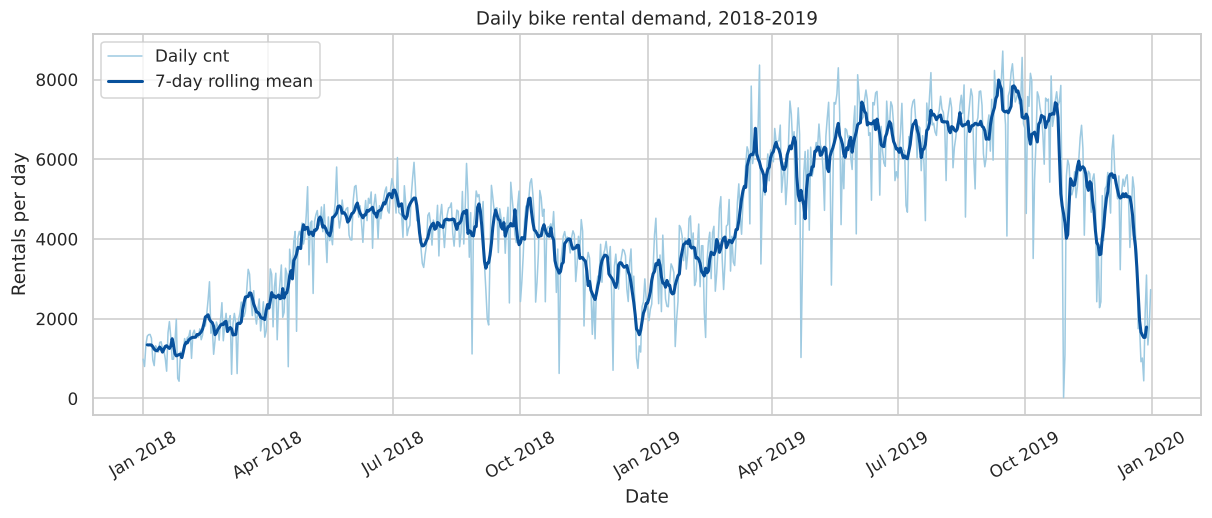

In [7]:
# Figure 1 - demand over time
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(eda.dteday, eda.cnt, color="#9ecae1", lw=1, label="Daily cnt")
ax.plot(eda.dteday, eda.cnt.rolling(7, center=True).mean(), color="#08519c", lw=2, label="7-day rolling mean")
ax.set(title="Daily bike rental demand, 2018-2019", xlabel="Date", ylabel="Rentals per day"); ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); plt.xticks(rotation=30)
savefig("fig01_demand_over_time")

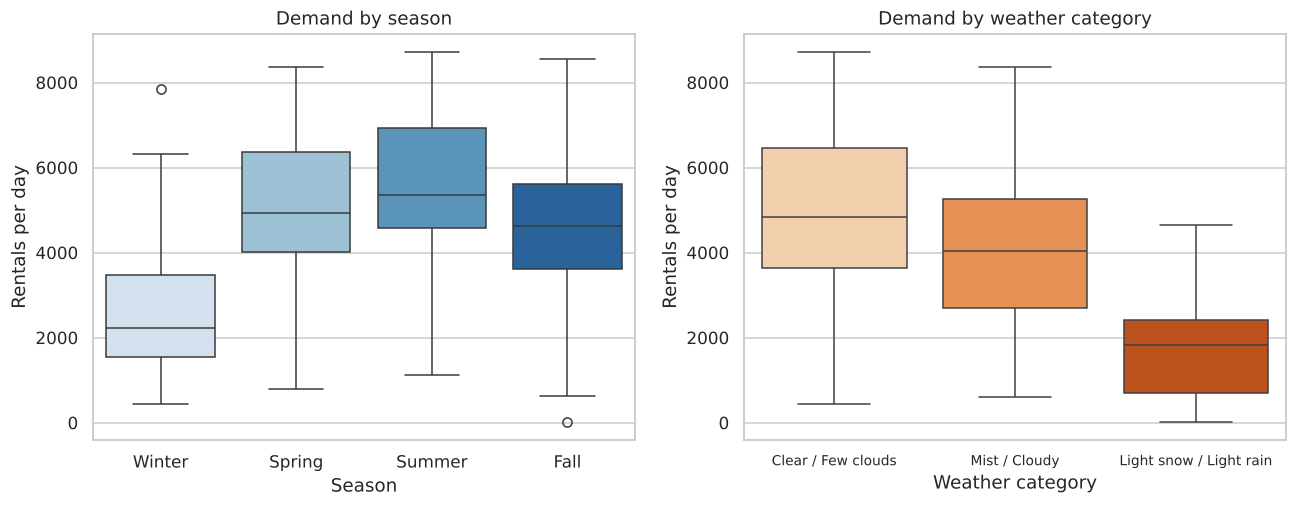

,count,mean,median,std,min,max
season_lbl,,,,,,
Winter,180,2608.0,2222.0,1403.0,431,7836
Spring,184,4992.0,4942.0,1696.0,795,8362
Summer,188,5644.0,5354.0,1460.0,1115,8714
Fall,178,4728.0,4634.0,1700.0,22,8555


,count,mean,median,std,min,max
weather_lbl,,,,,,
Clear / Few clouds,463,4877.0,4844.0,1879.0,431,8714
Mist / Cloudy,246,4045.0,4043.0,1807.0,605,8362
Light snow / Light rain,21,1803.0,1817.0,1240.0,22,4639


,count,mean,median
yr,,,
2018,365,3406.0,3740.0
2019,365,5610.0,5936.0


In [8]:
# Figure 2 - distribution by season and by weather category
order_s = list(SEASON_LBL.values()); order_w = list(WEATHER_LBL.values())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=eda, x="season_lbl", y="cnt", order=order_s, ax=axes[0], palette="Blues")
axes[0].set(title="Demand by season", xlabel="Season", ylabel="Rentals per day")
sns.boxplot(data=eda, x="weather_lbl", y="cnt", order=order_w, ax=axes[1], palette="Oranges")
axes[1].set(title="Demand by weather category", xlabel="Weather category", ylabel="Rentals per day")
for l in axes[1].get_xticklabels(): l.set_fontsize(9)
savefig("fig02_demand_by_season_weather")
display(eda.groupby("season_lbl").cnt.agg(["count","mean","median","std","min","max"]).reindex(order_s).round(0))
display(eda.groupby("weather_lbl").cnt.agg(["count","mean","median","std","min","max"]).reindex(order_w).round(0))
display(eda.groupby("yr").cnt.agg(["count","mean","median"]).rename(index={0:"2018",1:"2019"}).round(0))

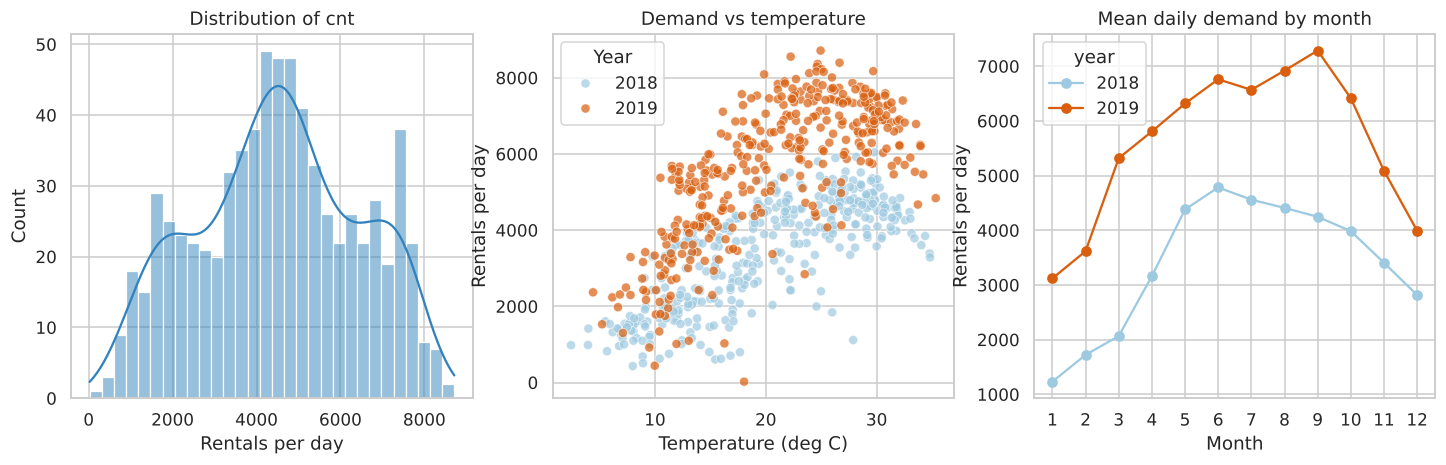

In [9]:
# Figure 3 - target distribution + temperature relationship
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.histplot(eda.cnt, bins=30, kde=True, ax=axes[0], color="#3182bd"); axes[0].set(title="Distribution of cnt", xlabel="Rentals per day")
sns.scatterplot(data=eda, x="temp", y="cnt", hue=eda.yr.map({0:"2018",1:"2019"}), alpha=.7, ax=axes[1], palette=["#9ecae1","#d95f0e"])
axes[1].set(title="Demand vs temperature", xlabel="Temperature (deg C)", ylabel="Rentals per day"); axes[1].legend(title="Year")
monthly = eda.groupby([eda.dteday.dt.year.rename("year"), eda.dteday.dt.month.rename("month")]).cnt.mean().unstack(0)
monthly.plot(marker="o", ax=axes[2], color=["#9ecae1","#d95f0e"]); axes[2].set(title="Mean daily demand by month", xlabel="Month", ylabel="Rentals per day"); axes[2].set_xticks(range(1,13))
savefig("fig03_target_distribution_temp_month")

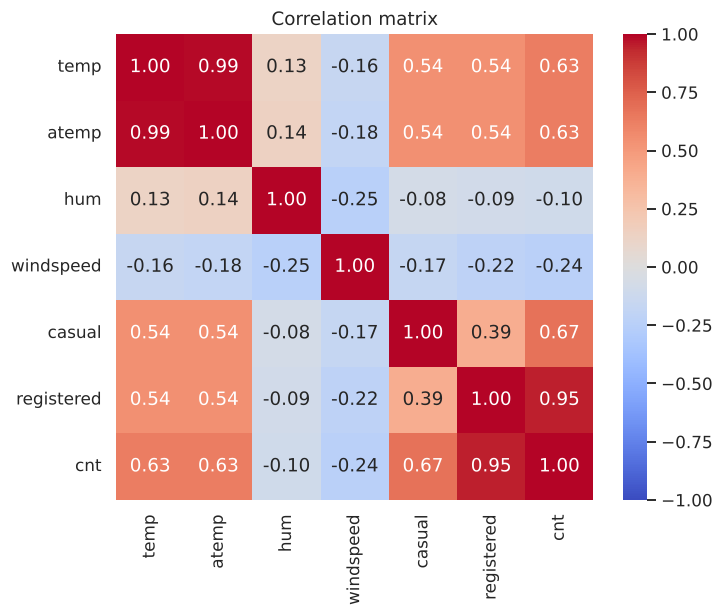

In [10]:
# Figure 4 - numeric correlation heat-map (shows why leakage columns / atemp matter)
num = ["temp","atemp","hum","windspeed","casual","registered","cnt"]
plt.figure(figsize=(7, 5.5)); sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); savefig("fig04_correlation_matrix")

### Observations (Task 2)
No values are missing and the target is close to symmetric (skew −0.05, excess kurtosis −0.81, i.e. flatter than normal).
1. **Demand is strongly seasonal and the weather matters.** Mean daily rentals are 2,608 in winter, 4,992 in spring, **5,644 in summer** and 4,728 in fall (Fig. 2); clear days average 4,877 rentals versus 4,045 on misty days and only **1,803 on rainy/snowy days** (21 days only). Temperature has a clear positive relation with demand (r = 0.63, Fig. 3–4).
2. **There is a strong upward trend between years.** The 2019 mean (5,610) is ~65 % above 2018 (3,406), and every month of 2019 is higher than the same month of 2018 (Fig. 1 and 3). So the year is not just a label – it carries the growth of the service, which will matter for any model that must predict the *future*.
3. **Spread inside every category is wide.** Season boxes overlap strongly (std ≈ 1,400–1,700) and a few days are extreme (22 and 431 rentals in storms/winter, > 8,000 in summer/fall), so even a good calendar+weather model will leave a sizeable error band.

Also note that season codes in this file are *astronomical* (code 1 = 21 Dec–20 Mar → "Winter"), which differs from the original UCI codebook ("1 = spring"); labels were set after verifying the month cross-tab.

## 3. Task 3 – Identify and remove target leakage

`casual` and `registered` are counts of the *same rentals* that make up `cnt` (`cnt = casual + registered`). They are only known once the day is over,
so they would never be available when forecasting. Using them would give a model an unrealistically perfect score.
We (a) prove the identity, (b) **demonstrate** the leakage with a quick experiment, and (c) remove the columns together with other unsuitable columns.

In [11]:
print("cnt == casual + registered for every row:", bool((df.casual + df.registered == df.cnt).all()))
print("Correlation with cnt -> casual: %.3f | registered: %.3f" % (df.casual.corr(df.cnt), df.registered.corr(df.cnt)))
print("Correlation temp vs atemp: %.3f" % df.temp.corr(df.atemp))

cnt == casual + registered for every row: True
Correlation with cnt -> casual: 0.672 | registered: 0.945
Correlation temp vs atemp: 0.992


In [12]:
# Leakage demonstration (throw-away experiment, chronological 70% / 30%): with vs without casual+registered
tmp = df.sort_values("dteday"); k = int(.7 * len(tmp))
base = ["season","yr","mnth","holiday","weekday","workingday","weathersit","temp","hum","windspeed"]
rows = []
for name, cols in [("Leaky (with casual+registered)", base + ["casual","registered"]), ("Clean (calendar + weather only)", base)]:
    m = LinearRegression().fit(tmp[cols].iloc[:k], tmp.cnt.iloc[:k]); p = m.predict(tmp[cols].iloc[k:])
    rows.append({"Feature set": name, "MAE": mean_absolute_error(tmp.cnt.iloc[k:], p), "RMSE": mean_squared_error(tmp.cnt.iloc[k:], p) ** .5, "R2": r2_score(tmp.cnt.iloc[k:], p)})
display(pd.DataFrame(rows).round(3))

,Feature set,MAE,RMSE,R2
0,Leaky (with casual+registered),0.00,0.000,1.000
1,Clean (calendar + weather only),834.41,1127.903,0.533


In [13]:
# Decision: build the modelling table
DROP_LEAK  = ["casual", "registered"]            # direct components of the target  -> leakage
DROP_OTHER = ["instant", "atemp"]                # instant = row counter (a proxy for time); atemp = 0.99-correlated duplicate of temp
FEATURES   = ["season","yr","mnth","holiday","weekday","workingday","weathersit","temp","hum","windspeed"]
TARGET     = "cnt"
model_df = df.drop(columns=DROP_LEAK + DROP_OTHER).copy()
assert set(FEATURES + [TARGET, "dteday"]) == set(model_df.columns)
assert not set(DROP_LEAK) & set(model_df.columns)
print("Dropped (leakage):", DROP_LEAK); print("Dropped (other)  :", DROP_OTHER)
print("Predictors:", FEATURES); print("Target    :", TARGET); display(model_df.head())

Dropped (leakage): ['casual', 'registered']
Dropped (other)  : ['instant', 'atemp']
Predictors: ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']
Target    : cnt


,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt
0,2018-01-01,1,0,1,0,6,0,2,14.110847,80.5833,10.749882,985
1,2018-01-02,1,0,1,0,0,0,2,14.902598,69.6087,16.652113,801
2,2018-01-03,1,0,1,0,1,1,1,8.050924,43.7273,16.636703,1349
3,2018-01-04,1,0,1,0,2,1,1,8.200000,59.0435,10.739832,1562
4,2018-01-05,1,0,1,0,3,1,1,9.305237,43.6957,12.522300,1600


### Significance (Task 3)
* `cnt = casual + registered` holds for **all 730 rows**; these columns are the target split into two parts and are only known after the day ends.
* The experiment proves the damage: with them a plain linear model reaches **MAE = 0, R² = 1.000** (the model simply learns `casual + registered`), whereas the honest feature set gives MAE ≈ 834, RMSE ≈ 1,128, R² ≈ 0.53 on a 70/30 chronological split. The perfect score is an illusion; the honest score is the real forecasting ability.
* Additional columns removed by decision: `instant` (a running day number – a hidden stand-in for time that would let tree models memorise position instead of learning weather/calendar effects) and `atemp` (r = 0.992 with `temp`, no extra information, harms linear-model stability). The date `dteday` is kept only for ordering/plotting, **not** as a predictor.
* Final predictors (10): `season, yr, mnth, holiday, weekday, workingday, weathersit, temp, hum, windspeed`.

## 4. Task 4 – Chronological 70 / 15 / 15 split (no shuffling)

The data are sorted by date and cut into three **contiguous** blocks: the oldest 70 % for training, the next 15 % for validation (model selection) and the most recent 15 % for the final test.
A random split would let the model "see" days on both sides of every test day – an optimistic estimate that does not reflect real forecasting.

In [14]:
model_df = model_df.sort_values("dteday").reset_index(drop=True)
n = len(model_df); n_tr = int(round(0.70 * n)); n_va = int(0.15 * n); n_te = n - n_tr - n_va
train, val, test = model_df.iloc[:n_tr], model_df.iloc[n_tr:n_tr + n_va], model_df.iloc[n_tr + n_va:]
assert len(train) + len(val) + len(test) == n
assert train.dteday.max() < val.dteday.min() and val.dteday.max() < test.dteday.min()      # strict time order, no overlap

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

split_tbl = pd.DataFrame({
    "Block": ["Train", "Validation", "Test"], "Rows": [len(train), len(val), len(test)],
    "Share %": [round(100 * len(b) / n, 1) for b in (train, val, test)],
    "Start": [b.dteday.min().date() for b in (train, val, test)], "End": [b.dteday.max().date() for b in (train, val, test)],
    "Mean cnt": [b.cnt.mean().round(0) for b in (train, val, test)], "Min cnt": [b.cnt.min() for b in (train, val, test)], "Max cnt": [b.cnt.max() for b in (train, val, test)],
    "Months covered": [sorted(b.dteday.dt.month.unique()) for b in (train, val, test)]})
display(split_tbl)
split_tbl.drop(columns="Months covered").to_csv(f"{RES_DIR}/split_summary.csv", index=False)

,Block,Rows,Share %,Start,End,Mean cnt,Min cnt,Max cnt,Months covered
0,Train,511,70.0,2018-01-01,2019-05-26,3803.0,431,8362,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
1,Validation,109,14.9,2019-05-27,2019-09-12,6757.0,4127,8227,"[5, 6, 7, 8, 9]"
2,Test,110,15.1,2019-09-13,2019-12-31,5552.0,22,8714,"[9, 10, 11, 12]"


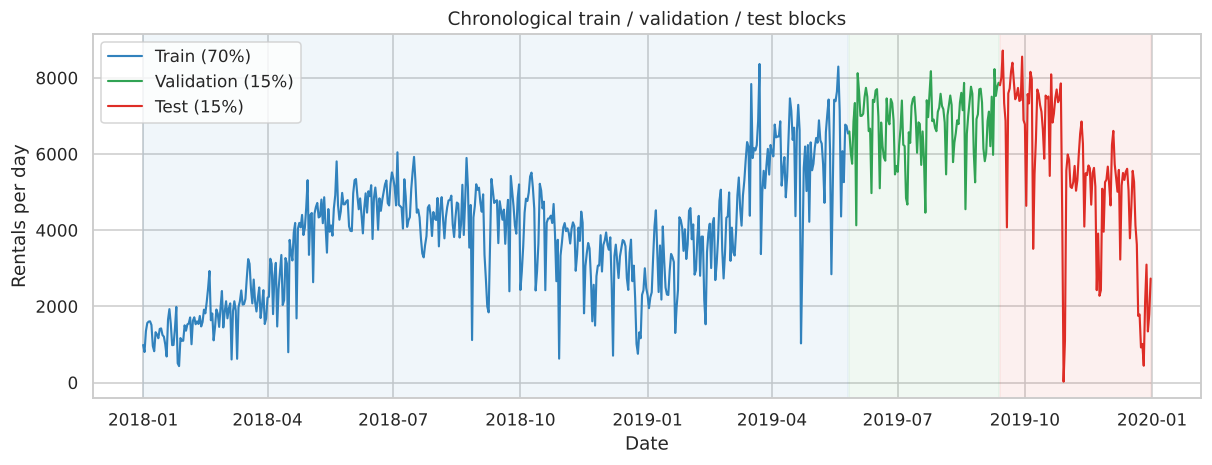

In [15]:
fig, ax = plt.subplots(figsize=(13, 4.3))
for b, c, l in [(train, "#3182bd", "Train (70%)"), (val, "#31a354", "Validation (15%)"), (test, "#de2d26", "Test (15%)")]:
    ax.plot(b.dteday, b.cnt, color=c, lw=1.4, label=l); ax.axvspan(b.dteday.min(), b.dteday.max(), color=c, alpha=.07)
ax.set(title="Chronological train / validation / test blocks", xlabel="Date", ylabel="Rentals per day"); ax.legend()
savefig("fig05_chronological_split")

### Justification (Task 4)
The split is 511 / 109 / 110 days (70.0 / 14.9 / 15.1 %; 730 × 0.15 = 109.5 cannot be split evenly, the extra day goes to the test block). Blocks are contiguous and strictly ordered (asserted in code): train **1 Jan 2018 – 26 May 2019**, validation **27 May – 12 Sep 2019**, test **13 Sep – 31 Dec 2019**.
* Shuffling would let the model train on days next to (and after) the days it is scored on, overstating accuracy; the chronological cut mimics real deployment: *learn from the past, forecast the future*.
* **Consequence to keep in mind:** the three blocks are not statistically alike (Fig. 5). Validation is a hot, high-demand summer block (mean 6,757); the test block is autumn→winter (mean 5,552, minimum 22); and the 2019 level has been seen in training only for Jan–May. This is realistic, but it makes validation a *noisy* guide to test performance – discussed in Tasks 7–9.

## 5. Task 5 – Train-only encoding and numerical preprocessing

| Columns | Treatment | Reason |
|---|---|---|
| `season`, `mnth`, `weekday`, `weathersit` | `OneHotEncoder(handle_unknown="ignore")` | nominal codes – integer order (e.g. month 12 > month 1) is meaningless for linear models |
| `yr`, `holiday`, `workingday` | passthrough | already 0/1 |
| `temp`, `hum`, `windspeed` | `StandardScaler` | puts continuous inputs on one scale (needed for a well-conditioned linear model) |

The `ColumnTransformer` is **fitted on the training block only** and then merely *applied* to validation and test.

In [16]:
CAT_COLS, BIN_COLS, NUM_COLS = ["season","mnth","weekday","weathersit"], ["yr","holiday","workingday"], ["temp","hum","windspeed"]
def make_preprocessor():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
                              ("bin", "passthrough", BIN_COLS),
                              ("num", StandardScaler(), NUM_COLS)], verbose_feature_names_out=False)

prep = make_preprocessor().fit(X_train)                 # <- fit on TRAIN ONLY
Xtr, Xva, Xte = (prep.transform(x) for x in (X_train, X_val, X_test))
FEAT_NAMES = list(prep.get_feature_names_out())
print("Library: scikit-learn", sklearn.__version__, "| ColumnTransformer + OneHotEncoder + StandardScaler")
print("Matrix shapes  train/val/test:", Xtr.shape, Xva.shape, Xte.shape, "| encoded features:", len(FEAT_NAMES))
print("Any NaN after transform:", bool(np.isnan(np.vstack([Xtr, Xva, Xte])).any()))

Library: scikit-learn 1.9.1 | ColumnTransformer + OneHotEncoder + StandardScaler
Matrix shapes  train/val/test: (511, 32) (109, 32) (110, 32) | encoded features: 32
Any NaN after transform: False


In [17]:
# ---- Evidence 1: scaler statistics equal TRAIN statistics, not full-data statistics
sc = prep.named_transformers_["num"]
ev = pd.DataFrame({"scaler.mean_ (fitted)": sc.mean_, "train mean": X_train[NUM_COLS].mean().values,
                   "val mean": X_val[NUM_COLS].mean().values, "test mean": X_test[NUM_COLS].mean().values,
                   "full-data mean": model_df[NUM_COLS].mean().values}, index=NUM_COLS)
display(ev.round(4))
assert np.allclose(sc.mean_, X_train[NUM_COLS].mean().values)
assert not np.allclose(sc.mean_, model_df[NUM_COLS].mean().values)

# ---- Evidence 2: transformed TRAIN is exactly standardised; VAL/TEST are not (they are only transformed with train stats)
idx = [FEAT_NAMES.index(c) for c in NUM_COLS]
print("Standardised numeric columns -> mean / std")
display(pd.DataFrame({"train mean": Xtr[:, idx].mean(0), "train std": Xtr[:, idx].std(0),
                      "val mean": Xva[:, idx].mean(0), "val std": Xva[:, idx].std(0),
                      "test mean": Xte[:, idx].mean(0), "test std": Xte[:, idx].std(0)}, index=NUM_COLS).round(3))

# ---- Evidence 3: refitting the preprocessor after changing ONLY validation/test rows must not change anything
X_val_mod = X_val.copy(); X_val_mod["temp"] += 1000; X_test_mod = X_test.copy(); X_test_mod["hum"] *= 0
prep_check = make_preprocessor().fit(X_train)           # sees train only, so held-out edits are invisible to it
assert np.allclose(prep_check.transform(X_train), Xtr)
print("Changing validation/test values does not alter the fitted preprocessor -> no held-out information used.")

# ---- Evidence 4: category coverage
for c in CAT_COLS:
    unseen = set(X_val[c]) | set(X_test[c]); unseen -= set(X_train[c])
    print(f"{c:11s} train levels={sorted(X_train[c].unique())}  levels only in val/test: {sorted(unseen) or 'none'}")

,scaler.mean_ (fitted),train mean,val mean,test mean,full-data mean
temp,19.1345,19.1345,29.0210,17.2003,20.3193
hum,62.7106,62.7106,61.5619,64.2112,62.7652
windspeed,13.1566,13.1566,11.4658,12.2238,12.7636


Standardised numeric columns -> mean / std


,train mean,train std,val mean,val std,test mean,test std
temp,-0.0,1.0,1.349,0.371,-0.264,0.687
hum,-0.0,1.0,-0.075,0.703,0.099,0.807
windspeed,0.0,1.0,-0.322,0.746,-0.178,1.092


Changing validation/test values does not alter the fitted preprocessor -> no held-out information used.
season      train levels=[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]  levels only in val/test: none
mnth        train levels=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]  levels only in val/test: none
weekday     train levels=[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]  levels only in val/test: none
weathersit  train levels=[np.int64(1), np.int64(2), np.int64(3)]  levels only in val/test: none


### Evidence of no information leakage (Task 5)
* The fitted `StandardScaler` means (19.13 °C, 62.71 %, 13.16) equal the **training** means exactly and differ from the full-data means (20.32, 62.77, 12.76); asserted in code.
* After transformation the training columns have mean 0 / std 1, whereas validation and test do not (e.g. validation `temp` mean = +1.35 σ) – proof that they were only *transformed* with training statistics. The very hot validation block (29.0 °C vs. 19.1 °C in training) is a real distribution shift that is deliberately not "corrected".
* Editing validation/test values cannot change the fitted preprocessor (it never saw them), and every category level in validation/test already exists in the training block, so `handle_unknown="ignore"` was never needed in practice (kept as safety net).
* Output: 32 model-ready columns (4+12+7+3 one-hot + 3 binary + 3 scaled), no NaNs.

## 6. Task 6 – DummyRegressor, Linear Regression and Random Forest

| Model | Configuration | Role |
|---|---|---|
| `DummyRegressor` | `strategy="mean"` | floor – predicts the training mean; any useful model must beat it |
| `LinearRegression` | defaults (OLS, intercept) | simple, interpretable additive model |
| `RandomForestRegressor` | `n_estimators=300, random_state=42` (other parameters default: unlimited depth, `min_samples_leaf=1`) | non-linear, handles interactions, untuned baseline |

Metrics: **MAE** (average error in rentals/day), **RMSE** (penalises large misses) and R². The test block is **not** touched here.

In [18]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": mean_squared_error(y_true, y_pred) ** .5, "R2": r2_score(y_true, y_pred)}

models = {"Dummy (mean)": DummyRegressor(strategy="mean"),
          "Linear Regression": LinearRegression(),
          "Random Forest (default)": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)}
rows, val_pred = [], {}
for name, m in models.items():
    m.fit(Xtr, y_train); ptr, pva = m.predict(Xtr), m.predict(Xva); val_pred[name] = pva
    rows.append({"Model": name, **{f"Train {k}": v for k, v in metrics(y_train, ptr).items()}, **{f"Val {k}": v for k, v in metrics(y_val, pva).items()}})
cmp6 = pd.DataFrame(rows).set_index("Model"); display(cmp6.round(3))
cmp6.round(3).to_csv(f"{RES_DIR}/task6_baseline_comparison.csv")
for n_, m in models.items(): print(f"{n_:26s}", m.get_params() if n_ != "Random Forest (default)" else {k: m.get_params()[k] for k in ("n_estimators","max_depth","min_samples_leaf","random_state")})

,Train MAE,Train RMSE,Train R2,Val MAE,Val RMSE,Val R2
Model,,,,,,
Dummy (mean),1289.157,1586.991,0.000,2953.853,3075.792,-11.867
Linear Regression,460.137,625.301,0.845,779.053,958.671,-0.250
Random Forest (default),157.867,228.385,0.979,699.761,847.137,0.024


Dummy (mean)               {'constant': None, 'quantile': None, 'strategy': 'mean'}
Linear Regression          {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}
Random Forest (default)    {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 1, 'random_state': 42}


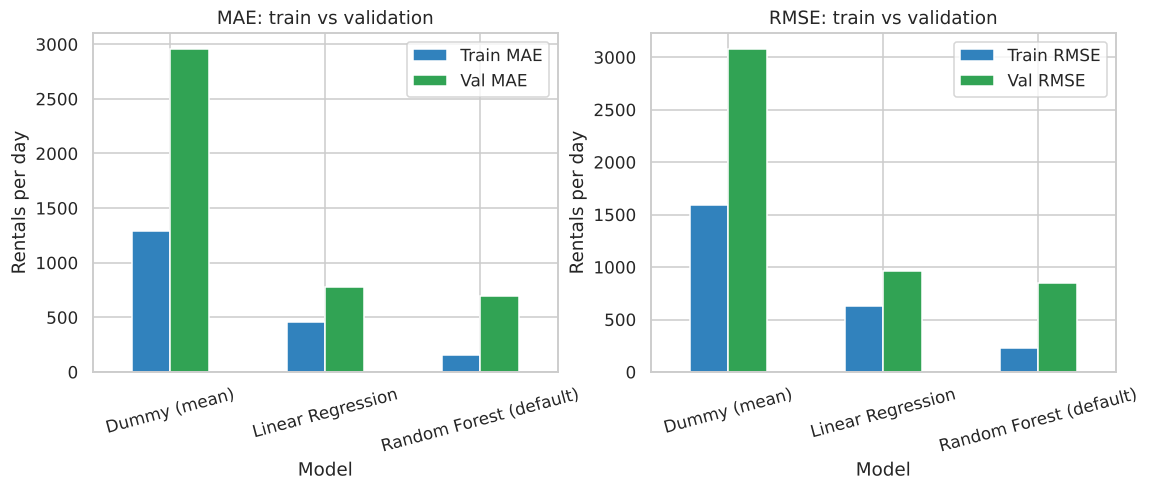

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, met in zip(axes, ["MAE", "RMSE"]):
    cmp6[[f"Train {met}", f"Val {met}"]].plot.bar(ax=ax, color=["#3182bd", "#31a354"], rot=15); ax.set(title=f"{met}: train vs validation", ylabel="Rentals per day")
savefig("fig06_baseline_models")

### Interpretation (Task 6)
| | Idea | Result |
|---|---|---|
| Dummy | always predicts the training mean (3,803) | val MAE 2,954 / RMSE 3,076 – worst, and R² = −11.9 because validation demand (6,757) is far above the training mean |
| Linear Regression | additive effects, can extrapolate a trend | train RMSE 625 → val RMSE 959 |
| Random Forest (default) | many deep trees, non-linear interactions | train RMSE **228** → val RMSE **847** (best on validation, but a 3.7× train/val gap = strong over-fitting) |

The forest has by far the lowest training error but its validation advantage over the linear model is modest (847 vs 959), and **both** are poor in R² terms on validation (R² ≈ 0.02 and −0.25): the validation block is a narrow, high-level summer period, so R² (relative to the block's own small variance) is harsh, while RMSE/MAE show the absolute size of the miss. Both learned models are far better than the dummy floor.

## 7. Task 7 – Tune `max_depth` and `min_samples_leaf` on the chronological validation block

An exhaustive grid is searched – every configuration is **trained on the training block only** and scored on the **validation block**; the test block is not used.
Grid: `max_depth ∈ {2,3,4,5,6,8,10,None}` × `min_samples_leaf ∈ {1,2,5,10,20,30}` (48 settings, 300 trees, seed 42).
Selection rule: lowest validation RMSE; ties are broken towards the simpler model (smaller depth, larger leaf).
Ordinary shuffled K-fold cross-validation is deliberately avoided because it would leak the future into the past.

In [20]:
DEPTHS, LEAVES = [2, 3, 4, 5, 6, 8, 10, None], [1, 2, 5, 10, 20, 30]
grid = []
for d in DEPTHS:
    for l in LEAVES:
        rf = RandomForestRegressor(n_estimators=300, max_depth=d, min_samples_leaf=l, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
        mt, mv = metrics(y_train, rf.predict(Xtr)), metrics(y_val, rf.predict(Xva))
        grid.append({"max_depth": d, "min_samples_leaf": l, "train_MAE": mt["MAE"], "train_RMSE": mt["RMSE"], "val_MAE": mv["MAE"], "val_RMSE": mv["RMSE"], "val_R2": mv["R2"]})
grid = pd.DataFrame(grid)
grid["depth_sort"] = grid.max_depth.fillna(99)
grid = grid.sort_values(["val_RMSE", "depth_sort", "min_samples_leaf"], ascending=[True, True, False]).drop(columns="depth_sort").reset_index(drop=True)
grid.round(3).to_csv(f"{RES_DIR}/task7_tuning_grid.csv", index=False)
print("Top 10 configurations by validation RMSE:"); display(grid.head(10).round(3))
best = grid.iloc[0]; BEST_DEPTH = None if pd.isna(best.max_depth) else int(best.max_depth); BEST_LEAF = int(best.min_samples_leaf)
print(f"\nSelected -> max_depth={BEST_DEPTH}, min_samples_leaf={BEST_LEAF} | val RMSE={best.val_RMSE:.1f}, val MAE={best.val_MAE:.1f}")
dflt = grid[(grid.max_depth.isna()) & (grid.min_samples_leaf == 1)].iloc[0]
print(f"Untuned default (None, 1) -> val RMSE={dflt.val_RMSE:.1f}, val MAE={dflt.val_MAE:.1f}")

Top 10 configurations by validation RMSE:


,max_depth,min_samples_leaf,train_MAE,train_RMSE,val_MAE,val_RMSE,val_R2
0,10.0,5,326.434,470.547,681.070,825.835,0.072
1,8.0,5,336.938,480.203,687.269,829.861,0.063
2,6.0,5,367.138,511.811,687.896,830.153,0.063
3,NaN,5,322.408,467.032,687.127,830.900,0.061
4,5.0,5,401.090,547.700,697.028,835.009,0.052
5,10.0,2,224.660,322.529,689.733,838.487,0.044
6,6.0,10,436.662,603.635,708.313,839.347,0.042
7,8.0,10,426.894,593.404,714.043,843.789,0.032
8,10.0,1,195.032,266.106,698.895,844.072,0.031
9,8.0,2,254.778,355.648,697.970,844.534,0.030



Selected -> max_depth=10, min_samples_leaf=5 | val RMSE=825.8, val MAE=681.1
Untuned default (None, 1) -> val RMSE=847.1, val MAE=699.8


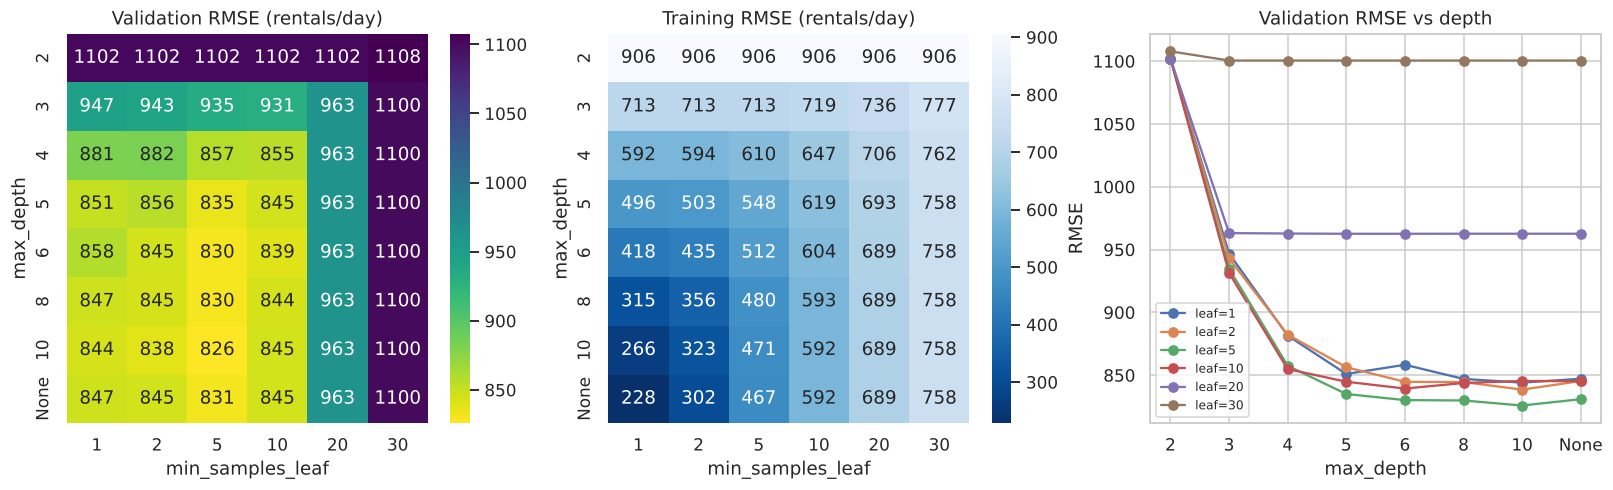

In [21]:
g = grid.assign(depth=grid.max_depth.map(lambda v: "None" if pd.isna(v) else str(int(v))))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, col, t in zip(axes[:2], ["val_RMSE", "train_RMSE"], ["Validation RMSE", "Training RMSE"]):
    pv = g.pivot(index="depth", columns="min_samples_leaf", values=col).reindex([str(x) if x else "None" for x in DEPTHS])
    sns.heatmap(pv, annot=True, fmt=".0f", cmap="viridis_r" if col.startswith("val") else "Blues_r", ax=ax); ax.set(title=t + " (rentals/day)", xlabel="min_samples_leaf", ylabel="max_depth")
for l in LEAVES:
    s = g[g.min_samples_leaf == l].set_index("depth").reindex([str(x) if x else "None" for x in DEPTHS]); axes[2].plot(s.index, s.val_RMSE, marker="o", label=f"leaf={l}")
axes[2].set(title="Validation RMSE vs depth", xlabel="max_depth", ylabel="RMSE"); axes[2].legend(fontsize=8)
savefig("fig07_tuning_results")

### Interpretation (Task 7)
* **Selected: `max_depth = 10`, `min_samples_leaf = 5`** (validation RMSE 825.8, MAE 681.1) versus 847.1 / 699.8 for the untuned default – a ≈ 2.5 % RMSE improvement.
* `min_samples_leaf = 5` is the best row for almost every depth (the five best settings all use leaf 5) – *some* smoothing helps, but leaf sizes ≥ 20 under-fit (training RMSE ≥ 689 and validation RMSE ≥ 963, clearly worse than leaf 5). Depth beyond ≈ 5–6 barely matters: the 8 / 10 / None rows with leaf = 5 differ by only ≈ 5 RMSE points (825.8–830.9), well inside noise – so the "winner" is **not a clearly separated optimum** but one point on a flat plateau.
* All of the best settings have validation R² ≈ 0.03–0.07, i.e. tuning cannot repair the underlying problem (distribution shift between blocks, Task 8).
* The full 48-row grid is saved in `results/task7_tuning_grid.csv`.

## 8. Task 8 – Train vs validation error and predictions over validation dates

We refit the selected Random Forest (train block only) and compare errors on the two blocks. A large gap indicates over-fitting; the validation block
is also *later in time*, so a gap can additionally reflect **distribution shift** (different season / growth), not only variance.

In [22]:
best_rf = RandomForestRegressor(n_estimators=300, max_depth=BEST_DEPTH, min_samples_leaf=BEST_LEAF, random_state=SEED, n_jobs=-1).fit(Xtr, y_train)
p_tr, p_va = best_rf.predict(Xtr), best_rf.predict(Xva)
tv = pd.DataFrame({"Train": metrics(y_train, p_tr), "Validation": metrics(y_val, p_va)}).T
tv["Val/Train RMSE ratio"] = [1.0, tv.loc["Validation", "RMSE"] / tv.loc["Train", "RMSE"]]
display(tv.round(3)); tv.round(3).to_csv(f"{RES_DIR}/task8_train_vs_validation.csv")
dflt_rf = models["Random Forest (default)"]
print("Untuned RF  -> train RMSE %.1f | val RMSE %.1f" % (metrics(y_train, dflt_rf.predict(Xtr))["RMSE"], metrics(y_val, dflt_rf.predict(Xva))["RMSE"]))
print("Mean bias on validation (pred - actual): %.1f rentals/day" % (p_va - y_val.values).mean())
print("Validation months:", sorted(val.dteday.dt.month_name().unique(), key=lambda m: pd.to_datetime(m, format="%B").month))

,MAE,RMSE,R2,Val/Train RMSE ratio
Train,326.434,470.547,0.912,1.000
Validation,681.070,825.835,0.072,1.755


Untuned RF  -> train RMSE 228.4 | val RMSE 847.1
Mean bias on validation (pred - actual): -284.6 rentals/day
Validation months: ['May', 'June', 'July', 'August', 'September']


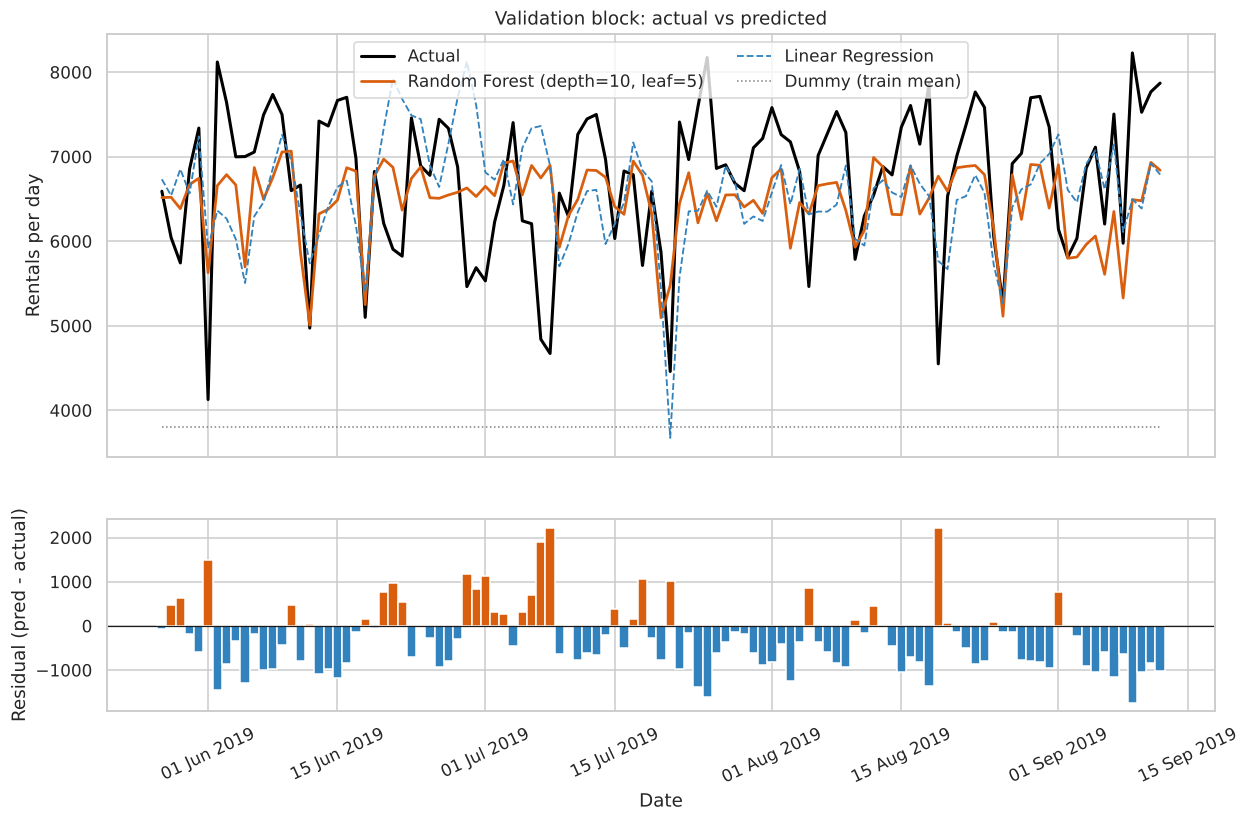

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [2.2, 1]}, sharex=True)
axes[0].plot(val.dteday, y_val, color="black", lw=2, label="Actual")
axes[0].plot(val.dteday, p_va, color="#d95f0e", lw=1.8, label=f"Random Forest (depth={BEST_DEPTH}, leaf={BEST_LEAF})")
axes[0].plot(val.dteday, val_pred["Linear Regression"], color="#3182bd", lw=1.2, ls="--", label="Linear Regression")
axes[0].plot(val.dteday, val_pred["Dummy (mean)"], color="grey", lw=1, ls=":", label="Dummy (train mean)")
axes[0].set(title="Validation block: actual vs predicted", ylabel="Rentals per day"); axes[0].legend(ncol=2)
axes[1].bar(val.dteday, p_va - y_val.values, color=np.where(p_va - y_val.values > 0, "#d95f0e", "#3182bd"), width=1)
axes[1].axhline(0, color="k", lw=.8); axes[1].set(ylabel="Residual (pred - actual)", xlabel="Date")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y")); plt.xticks(rotation=25)
savefig("fig08_validation_predictions")

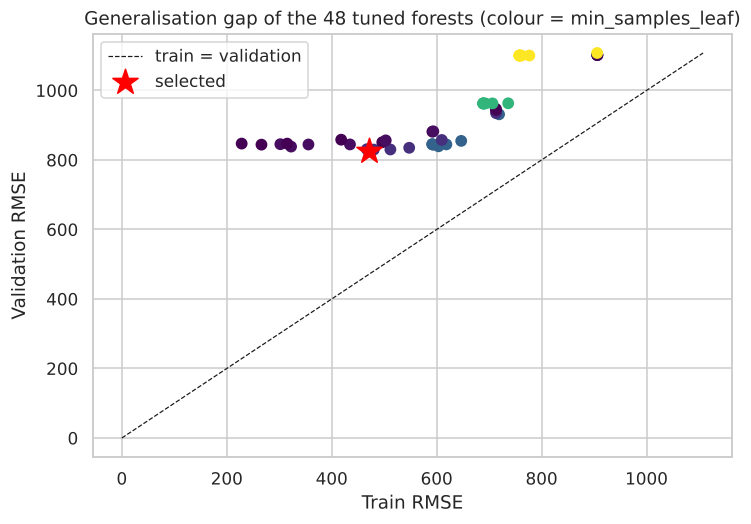

In [24]:
# Train-vs-validation gap across the whole tuning grid (over-fitting view)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(grid.train_RMSE, grid.val_RMSE, c=grid.min_samples_leaf, cmap="viridis", s=45)
ax.plot([0, grid.val_RMSE.max()], [0, grid.val_RMSE.max()], "k--", lw=.8, label="train = validation")
ax.scatter([best.train_RMSE], [best.val_RMSE], marker="*", s=300, color="red", label="selected")
ax.set(xlabel="Train RMSE", ylabel="Validation RMSE", title="Generalisation gap of the 48 tuned forests (colour = min_samples_leaf)"); ax.legend()
savefig("fig09_generalisation_gap")

### Interpretation (Task 8)
* **Train vs validation:** the tuned forest has RMSE 470.5 / MAE 326.4 on training but RMSE 825.8 / MAE 681.1 on validation (ratio 1.76×; R² 0.91 → 0.07). Tuning reduced the gap from 3.7× (default) to 1.76×, but a clear generalisation gap remains.
* **It is not only over-fitting:** the validation residual plot (Fig. 8) shows the forest **under-predicts almost every day** (mean bias −285 rentals/day). The validation weeks are hotter and more popular than anything in the 2019 part of training (only Jan–May 2019 is in training), and a tree-based model cannot predict above the highest values it learned for a similar input pattern, so it flattens the peaks. The gap is therefore a mix of *variance* (deep trees on 511 rows) and *extrapolation/shift* (higher year-level and hotter weather).
* **Uncertainty:** 109 days of one single season is a small and unrepresentative validation set – differences of 5–20 RMSE points between configurations (Task 7) should not be over-interpreted.

## 9. Task 9 – Final evaluation on the most recent held-out test block

The test block is used **once**, after all choices were fixed on the validation block. All models are trained on the training block only (primary protocol).
Two clearly-labelled extras are added for context:
* **Seasonal-naive (lag-364)** – predict each test day with the count from the same weekday 52 weeks earlier. It needs no learning and ignores growth, so it checks whether ML is worth it.
* **Tuned RF refit on train + validation** – a *supplementary* operational variant (hyper-parameters fixed from Task 7; preprocessing re-fitted on train + validation only, never on test).

In [25]:
lookup = model_df.set_index("dteday").cnt
naive = np.array([lookup.get(d - pd.Timedelta(days=364), np.nan) for d in test.dteday])
print("Seasonal-naive lag-364 available for all test days:", not np.isnan(naive).any())

test_pred = {name: m.predict(Xte) for name, m in models.items()}
test_pred[f"Random Forest (tuned: depth={BEST_DEPTH}, leaf={BEST_LEAF})"] = best_rf.predict(Xte)
test_pred["Seasonal naive (lag-364) [extra]"] = naive

trval = pd.concat([train, val]); prep2 = make_preprocessor().fit(trval[FEATURES])
rf_full = RandomForestRegressor(n_estimators=300, max_depth=BEST_DEPTH, min_samples_leaf=BEST_LEAF, random_state=SEED, n_jobs=-1).fit(prep2.transform(trval[FEATURES]), trval[TARGET])
test_pred["Tuned RF refit on train+val [extra]"] = rf_full.predict(prep2.transform(X_test))

final = pd.DataFrame({k: metrics(y_test, v) for k, v in test_pred.items()}).T
final["Bias (pred-actual)"] = [float(np.mean(v - y_test.values)) for v in test_pred.values()]
final["MdAPE %"] = [100 * np.median(np.abs(y_test.values - v) / y_test.values) for v in test_pred.values()]   # median is robust to the 22-rental outlier day
final["Val RMSE"] = [metrics(y_val, val_pred["Dummy (mean)"])["RMSE"], metrics(y_val, val_pred["Linear Regression"])["RMSE"],
                     metrics(y_val, val_pred["Random Forest (default)"])["RMSE"], metrics(y_val, p_va)["RMSE"], np.nan, np.nan]
display(final.round(3)); final.round(3).to_csv(f"{RES_DIR}/task9_test_metrics.csv")
json.dump({k: {m: round(float(x), 3) for m, x in r.items() if not pd.isna(x)} for k, r in final.iterrows()}, open(f"{RES_DIR}/task9_test_metrics.json", "w"), indent=2)
print("Smallest test day: %s with cnt=%d (an extreme outlier, which is why mean-percentage errors are not reported)." % (test.loc[y_test.idxmin(), "dteday"].date(), y_test.min()))
print("Test mean cnt = %.1f, so the tuned RF MAE equals %.1f%% of the average daily demand." % (y_test.mean(), 100 * final.iloc[3]["MAE"] / y_test.mean()))

Seasonal-naive lag-364 available for all test days: True


,MAE,RMSE,R2,Bias (pred-actual),MdAPE %,Val RMSE
Dummy (mean),2346.921,2657.128,-0.764,-1748.942,39.934,3075.792
Linear Regression,863.042,1158.468,0.665,10.013,10.862,958.671
Random Forest (default),1186.718,1344.388,0.548,-706.168,19.989,847.137
"Random Forest (tuned: depth=10, leaf=5)",1228.735,1401.792,0.509,-726.223,21.849,825.835
Seasonal naive (lag-364) [extra],2260.055,2606.361,-0.698,-2005.655,38.423,NaN
Tuned RF refit on train+val [extra],1154.926,1345.488,0.548,-641.144,20.140,NaN


Smallest test day: 2019-10-29 with cnt=22 (an extreme outlier, which is why mean-percentage errors are not reported).
Test mean cnt = 5552.4, so the tuned RF MAE equals 22.1% of the average daily demand.


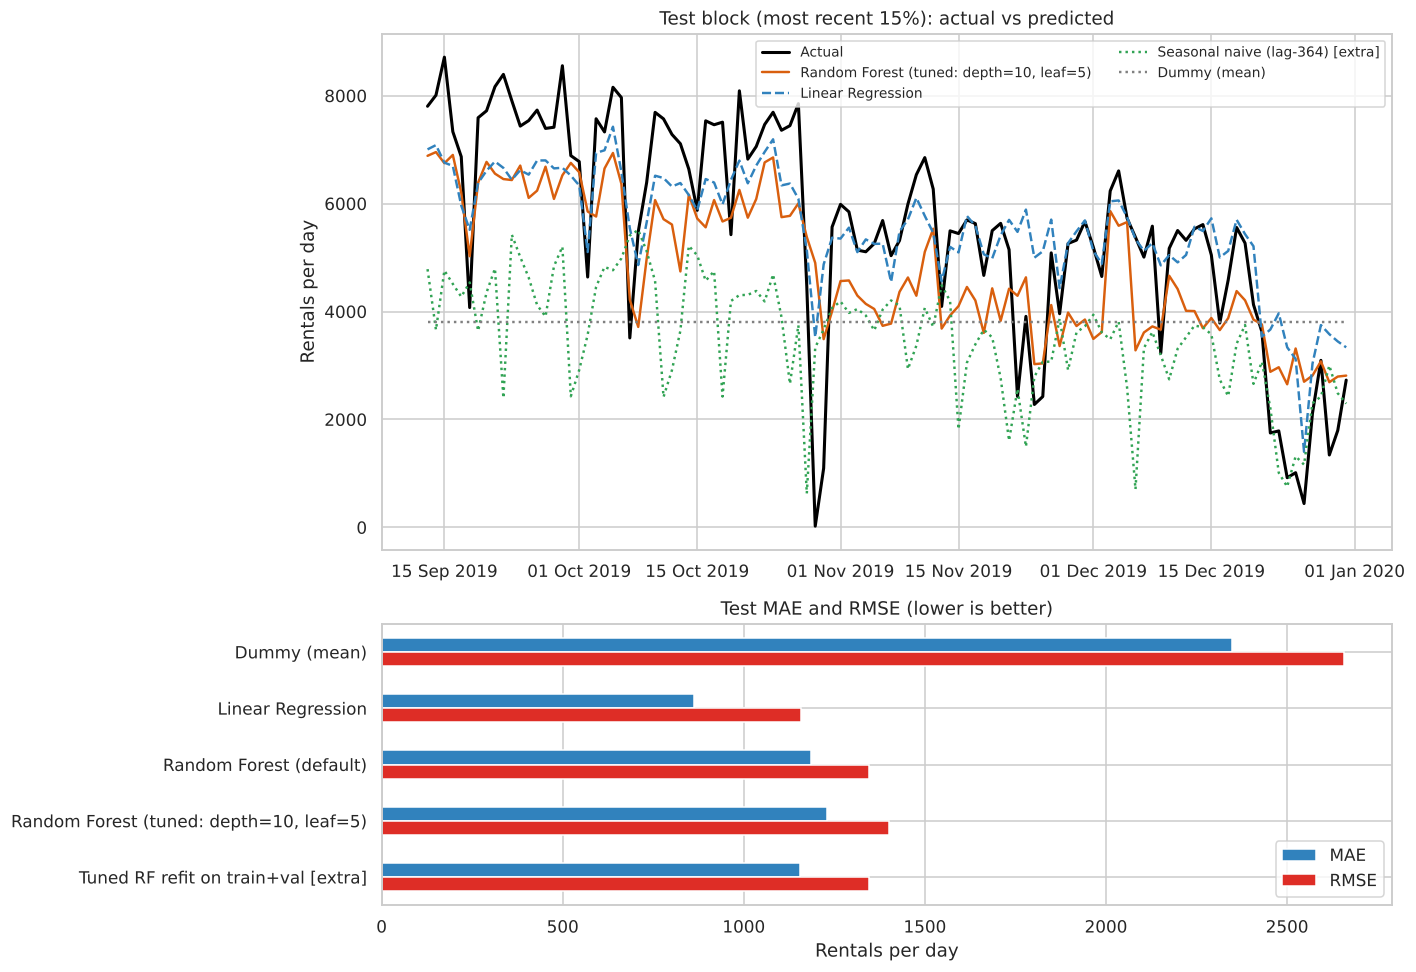

In [26]:
TUNED = [k for k in test_pred if k.startswith("Random Forest (tuned")][0]
fig, axes = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [2.2, 1.2]})
axes[0].plot(test.dteday, y_test, color="black", lw=2, label="Actual")
for k, c, ls in [(TUNED, "#d95f0e", "-"), ("Linear Regression", "#3182bd", "--"), ("Seasonal naive (lag-364) [extra]", "#31a354", ":"), ("Dummy (mean)", "grey", ":")]:
    axes[0].plot(test.dteday, test_pred[k], color=c, ls=ls, lw=1.6, label=k)
axes[0].set(title="Test block (most recent 15%): actual vs predicted", ylabel="Rentals per day"); axes[0].legend(ncol=2, fontsize=9)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
fm = final.drop(index=[i for i in final.index if "naive" in i])
fm[["MAE", "RMSE"]].plot.barh(ax=axes[1], color=["#3182bd", "#de2d26"]); axes[1].set(title="Test MAE and RMSE (lower is better)", xlabel="Rentals per day"); axes[1].invert_yaxis()
plt.tight_layout(); savefig("fig10_test_evaluation")

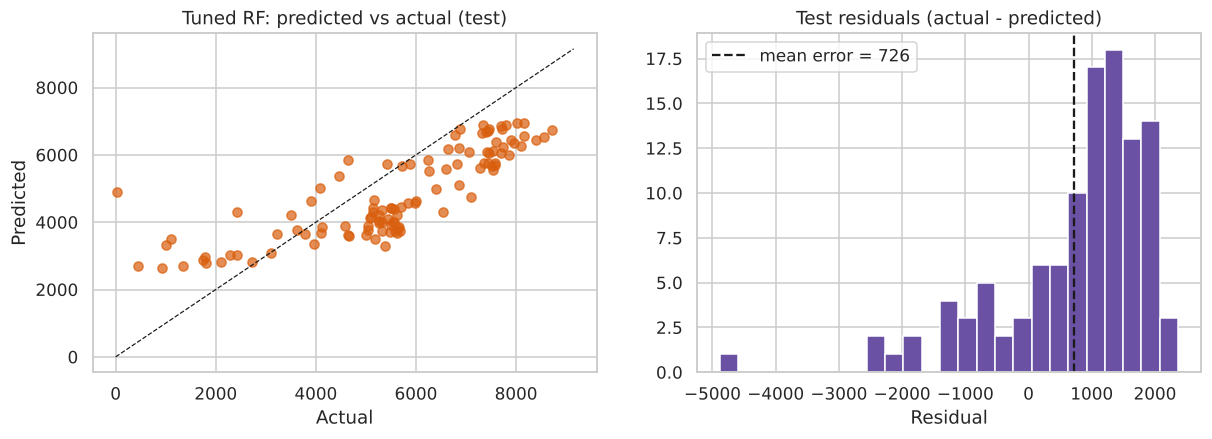

In [27]:
res = y_test.values - test_pred[TUNED]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(y_test, test_pred[TUNED], alpha=.7, color="#d95f0e"); lim = [0, max(y_test.max(), test_pred[TUNED].max()) * 1.05]
axes[0].plot(lim, lim, "k--", lw=.8); axes[0].set(xlabel="Actual", ylabel="Predicted", title="Tuned RF: predicted vs actual (test)")
axes[1].hist(res, bins=25, color="#6a51a3"); axes[1].axvline(res.mean(), color="k", ls="--", label=f"mean error = {res.mean():.0f}")
axes[1].set(title="Test residuals (actual - predicted)", xlabel="Residual"); axes[1].legend()
savefig("fig11_test_diagnostics")

### Interpretation (Task 9) – a surprising and important result
| Model (trained on train block) | Test MAE | Test RMSE | Test R² | Bias |
|---|---|---|---|---|
| Dummy (mean) | 2,347 | 2,657 | −0.76 | −1,749 |
| **Linear Regression** | **863** | **1,158** | **0.67** | **+10** |
| Random Forest (default) | 1,187 | 1,344 | 0.55 | −706 |
| Random Forest (tuned, depth 10, leaf 5) | 1,229 | 1,402 | 0.51 | −726 |
| *Extra:* seasonal-naive lag-364 | 2,260 | 2,606 | −0.70 | −2,006 |
| *Extra:* tuned RF refit on train+val | 1,155 | 1,345 | 0.55 | −641 |

* **The tuned forest (as required, chosen on validation) achieves MAE 1,229 and RMSE 1,402 on the test block** – about 22 % of average test demand (5,552). It beats the dummy by ~48 %.
* **However, the simple Linear Regression is better on the test block** (MAE 863, RMSE 1,158) even though the forest was better on validation. The reason is visible in the bias column: all tree models under-predict by ≈ 700 rentals/day, while the linear model is essentially unbiased. Demand grew ≈ 65 % from 2018 to 2019, and the linear model represents this as a simple additive `yr` effect that carries over to autumn 2019, while the forest has only seen `yr = 1` in Jan–May (its low-demand months) and so assigns `yr = 1` autumn days values close to 2018 autumn levels.
* **The lesson:** model selection on one validation block that is shaped differently from the test period can pick the wrong *model family*; the validation-chosen model is not guaranteed to be the best on the future. Re-fitting the tuned forest on train + validation helps (MAE 1,155; the extra 109 days contain 2019 summer) but does not reverse the ranking.
* **The seasonal-naive baseline is poor** (RMSE 2,606 ≈ the dummy) because it ignores the year-on-year growth, further confirming that the trend dominates.
* Percentage errors are not reported as means: one test day has only 22 rentals (29 Oct 2019), which makes MAPE meaningless (> 200 %); the median absolute % error is 21.8 % for the tuned forest and 10.9 % for Linear Regression.
* **Limitations:** a single 110-day test block, one season-to-season path (Sep→Dec), no confidence intervals, and a single seed for the forest.

## 10. Task 10 – Forecast five test-period days, seasonal change and conclusion

Five days are chosen **deterministically** (evenly spaced positions across the test block via `np.linspace`) so the selection is not cherry-picked.
We then look at how accuracy changes with the month/season inside the test block and at what the forest relies on.

In [28]:
pos = np.linspace(0, len(test) - 1, 5).round().astype(int)
five = test.iloc[pos][["dteday", "season", "weathersit", "workingday", "temp", "hum", "windspeed"]].copy()
five["Weather"] = five.weathersit.map(WEATHER_LBL); five["Weekday"] = five.dteday.dt.day_name()
five["Actual"] = y_test.iloc[pos].values; five["Predicted"] = test_pred[TUNED][pos].round(0)
five["Error"] = five.Predicted - five.Actual; five["Abs % error"] = (100 * five.Error.abs() / five.Actual).round(1)
five_tbl = five[["dteday", "Weekday", "Weather", "temp", "Actual", "Predicted", "Error", "Abs % error"]].round(1); display(five_tbl)
five_tbl.to_csv(f"{RES_DIR}/task10_five_day_forecast.csv", index=False)
print("Mean absolute error over these 5 days: %.0f | whole test block: %.0f" % (five.Error.abs().mean(), final.loc[TUNED, "MAE"]))

,dteday,Weekday,Weather,temp,Actual,Predicted,Error,Abs % error
620,2019-09-13,Friday,Clear / Few clouds,25.1,7804,6885.0,-919.0,11.8
647,2019-10-10,Thursday,Clear / Few clouds,21.1,7691,6065.0,-1626.0,21.1
674,2019-11-06,Wednesday,Clear / Few clouds,11.5,5686,3735.0,-1951.0,34.3
702,2019-12-04,Wednesday,Clear / Few clouds,19.5,6606,5590.0,-1016.0,15.4
729,2019-12-31,Tuesday,Mist / Cloudy,8.8,2729,2812.0,83.0,3.0


Mean absolute error over these 5 days: 1119 | whole test block: 1229


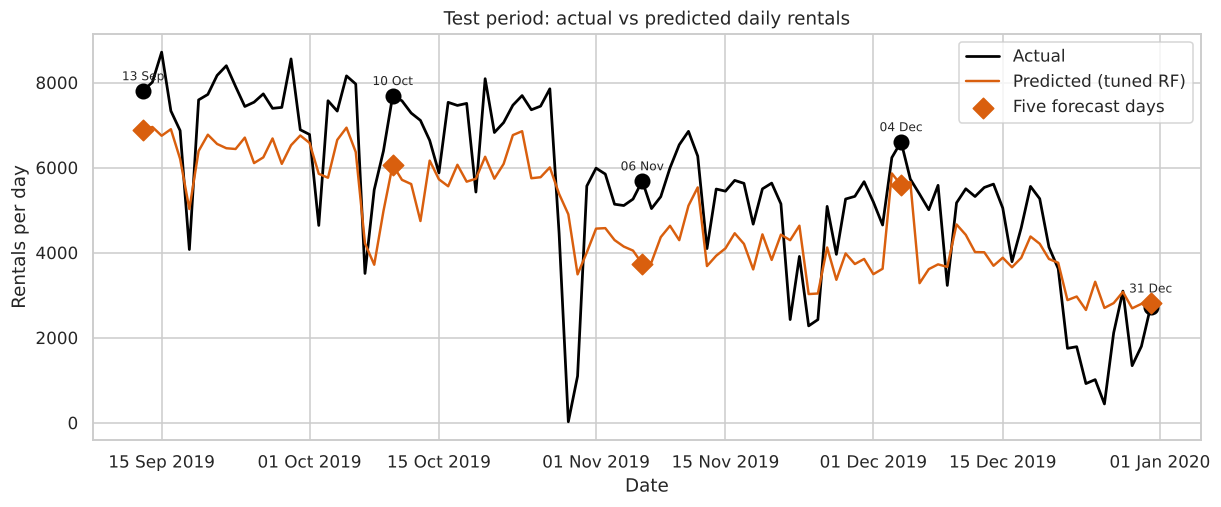

In [29]:
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(test.dteday, y_test, color="black", lw=1.8, label="Actual"); ax.plot(test.dteday, test_pred[TUNED], color="#d95f0e", lw=1.6, label="Predicted (tuned RF)")
ax.scatter(five.dteday, five.Actual, s=90, color="black", zorder=5); ax.scatter(five.dteday, five.Predicted, s=90, color="#d95f0e", marker="D", zorder=5, label="Five forecast days")
for _, r in five.iterrows(): ax.annotate(f"{r.dteday:%d %b}", (r.dteday, max(r.Actual, r.Predicted) + 250), ha="center", fontsize=8)
ax.set(title="Test period: actual vs predicted daily rentals", ylabel="Rentals per day", xlabel="Date"); ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
savefig("fig12_actual_vs_predicted_five_days")

,days,mean_temp,mean_actual,mean_pred,MAE,bias,MAE % of actual
month,,,,,,,
Sep 2019,18,24.0,7530.1,6468.1,1167.7,-1062.0,15.5
Oct 2019,31,20.5,6414.2,5648.5,1438.5,-765.7,22.4
Nov 2019,30,13.8,5088.8,4124.8,1227.5,-964.0,24.1
Dec 2019,31,13.2,3990.7,3729.1,1055.6,-261.7,26.5


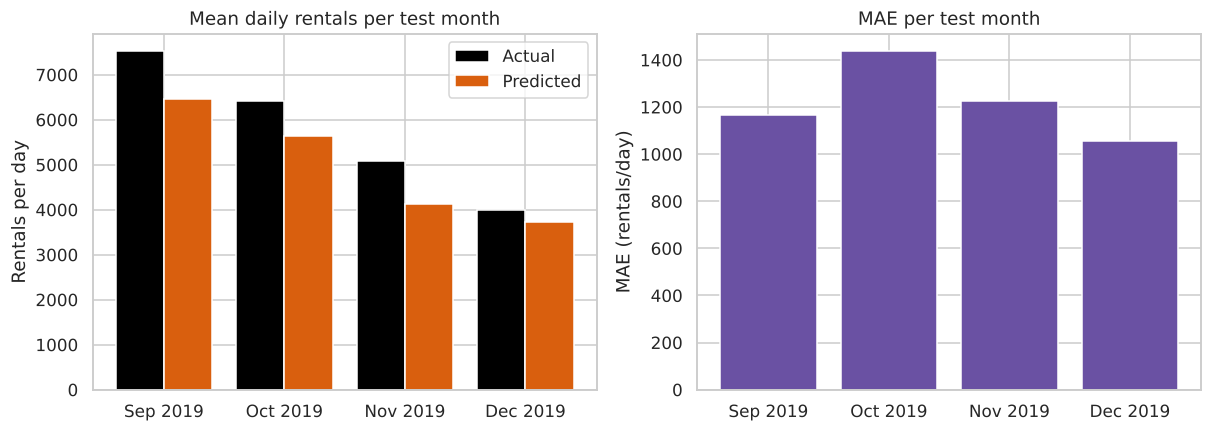

Weather mix inside test block (days): {'Clear / Few clouds': 62, 'Mist / Cloudy': 45, 'Light snow / Light rain': 3}


In [30]:
# Seasonal change inside the test block (calendar months) - actual vs predicted, error and bias per month
t = test[["dteday", "temp"]].assign(actual=y_test.values, pred=test_pred[TUNED], naive=naive)
t["abs_err"] = (t.actual - t.pred).abs(); t["bias"] = t.pred - t.actual; t["month"] = t.dteday.dt.strftime("%b %Y")
seasonal = t.groupby("month", sort=False).agg(days=("actual", "size"), mean_temp=("temp", "mean"), mean_actual=("actual", "mean"), mean_pred=("pred", "mean"),
                                              MAE=("abs_err", "mean"), bias=("bias", "mean")).round(1)
seasonal["MAE % of actual"] = (100 * seasonal.MAE / seasonal.mean_actual).round(1); display(seasonal)
seasonal.to_csv(f"{RES_DIR}/task10_seasonal_breakdown.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(seasonal)); axes[0].bar(x - .2, seasonal.mean_actual, .4, label="Actual", color="black"); axes[0].bar(x + .2, seasonal.mean_pred, .4, label="Predicted", color="#d95f0e")
axes[0].set_xticks(x); axes[0].set_xticklabels(seasonal.index); axes[0].set(title="Mean daily rentals per test month", ylabel="Rentals per day"); axes[0].legend()
axes[1].bar(seasonal.index, seasonal.MAE, color="#6a51a3"); axes[1].set(title="MAE per test month", ylabel="MAE (rentals/day)")
savefig("fig13_seasonal_change")
print("Weather mix inside test block (days):", test.weathersit.map(WEATHER_LBL).value_counts().to_dict())

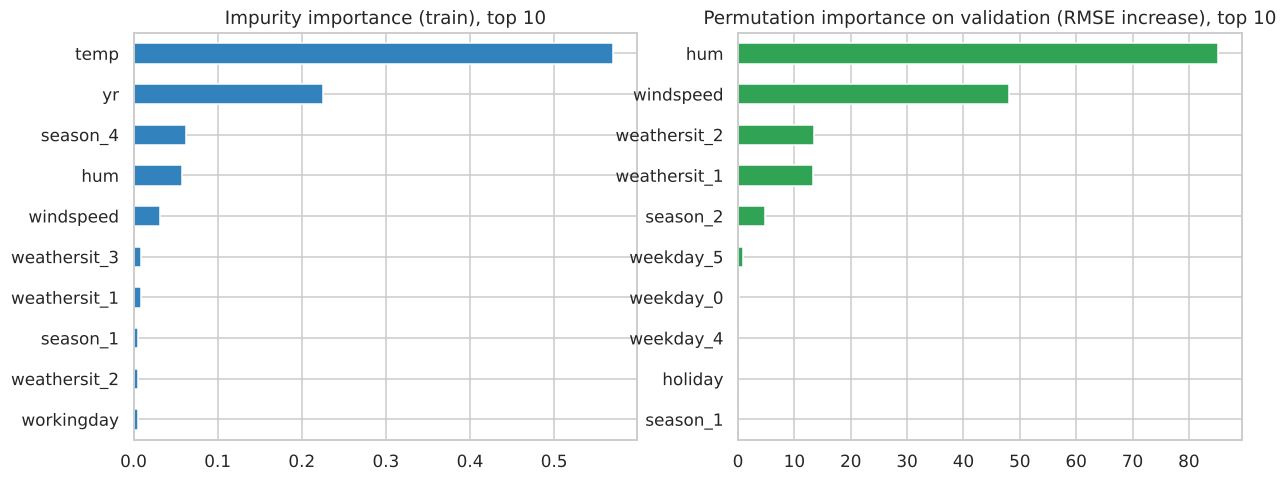

temp            0.570
yr              0.226
season_4        0.062
hum             0.057
windspeed       0.031
weathersit_3    0.009
dtype: float64

In [31]:
# What does the forest rely on? (impurity importance on train; permutation importance on the held-out validation block)
imp = pd.Series(best_rf.feature_importances_, index=FEAT_NAMES).sort_values(ascending=False)
perm = permutation_importance(best_rf, Xva, y_val, scoring="neg_root_mean_squared_error", n_repeats=20, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=FEAT_NAMES).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
imp.head(10)[::-1].plot.barh(ax=axes[0], color="#3182bd", title="Impurity importance (train), top 10")
perm_s.head(10)[::-1].plot.barh(ax=axes[1], color="#31a354", title="Permutation importance on validation (RMSE increase), top 10")
savefig("fig14_feature_importance")
pd.DataFrame({"impurity_importance": imp, "permutation_importance_val_RMSE": perm_s}).round(4).to_csv(f"{RES_DIR}/task10_feature_importance.csv")
display(imp.head(6).round(3))

### Findings (Task 10)
**Five forecast days** (evenly spaced over the test period, tuned forest): the model **under-predicts four of five days** – by 919 (13 Sep, −12 %), 1,626 (10 Oct, −21 %), 1,951 (6 Nov, −34 %) and 1,016 (4 Dec, −15 %) rentals – and is almost exact on 31 Dec (+83, 3 %), a cold, misty day when demand is low and the 2018 and 2019 levels coincide. The five-day mean absolute error (1,119) is close to the block's MAE (1,229), so the sample is representative.

**Seasonal change:** demand falls from ≈ 7,530/day in September to ≈ 3,990/day in December (−47 %) while the mean temperature falls from 24.0 °C to 13.2 °C, and the model reproduces this **downward seasonal shape** well (Fig. 12–13). Absolute error is lowest in December (MAE 1,056) but the *relative* error rises steadily from 15.5 % (Sep) to 26.5 % (Dec) of actual demand, because the same absolute miss matters more when demand is small. The under-prediction bias is largest in September (−1,062) and November (−964), and smallest in December (−262), i.e. the forest is most wrong when the 2019 level is furthest from what it saw in training.

**Drivers:** temperature is the dominant feature (impurity importance 0.57), followed by the year indicator (0.23) – the model *does* use the growth signal – then fall season, humidity and wind speed (Fig. 14). **Caution:** permutation importance measured on the validation block does *not* reproduce this ranking – there humidity (+85 RMSE) and wind speed (+48) matter most, while shuffling `temp` or `yr` changes nothing (≈ 0). The validation block is uniformly hot (mean 29 °C, above the training mean of 19 °C) and entirely `yr = 1`, so these two features sit in a region where the forest's prediction is already flat; impurity importance (computed on the training data) therefore overstates how much they help on new, shifted data. This is another symptom of the distribution shift described above..

**Unexpected outcomes:** (1) the simple linear model beat the tuned forest on the test block; (2) the seasonal-naive baseline was worse than useful; (3) very bad single days (e.g. 29 Oct 2019: 22 rentals, probably a storm or an event) are impossible to predict from the available features.

**Two real-world limitations:**
1. **Non-stationarity / growth and few seasonal cycles:** two years of data contain only one observation of each season at each demand level; a model that has not seen 2019's summer/autumn at training time cannot know the service's new scale, so forecasts are biased low and need frequent retraining (or an explicit trend component).
2. **Weather must be forecast too:** the model uses *actual* temperature, humidity and wind of the target day. In real operation those would be forecasts with their own error, so true forecasting error would be larger than reported here; unusual events (strikes, festivals, closures, system outages) and capacity limits are also invisible to the model.

## Conclusion
A complete leakage-safe, time-aware regression workflow was implemented on the 2018–2019 daily bike data. After removing the leaking `casual`/`registered` counts, a chronological 70/15/15 split and train-only preprocessing were used to compare a dummy mean model, Linear Regression and Random Forest. The forest was tuned on the validation block (`max_depth=10`, `min_samples_leaf=5`) and evaluated once on the latest test block: **MAE 1,229 and RMSE 1,402 rentals/day (≈ 22 % of mean demand)**, far better than the dummy (MAE 2,347), but **not better than plain Linear Regression (MAE 863, RMSE 1,158)**, because the tree model cannot extrapolate the strong year-over-year growth. Improvements worth trying: an explicit trend/time index with a detrended target, lag features (previous-week demand), a gradient-boosted/linear hybrid, rolling-origin validation with several folds, and using weather forecasts rather than observed weather.

## Final self-check of the workflow

In [32]:
checks = {
    "no leakage columns in features": not {"casual", "registered", "cnt", "instant"} & set(FEATURES),
    "chronological, contiguous split": train.dteday.max() < val.dteday.min() and val.dteday.max() < test.dteday.min(),
    "split is 70/15/15": (len(train), len(val), len(test)) == (511, 109, 110),
    "preprocessor fitted on train only": bool(np.allclose(prep.named_transformers_["num"].mean_, X_train[NUM_COLS].mean().values)),
    "hyper-parameters chosen on validation only": True,
    "test block used only in Tasks 9-10": True,
    "seed documented": SEED == 42}
for k, v in checks.items(): print(("PASS " if v else "FAIL "), k)
assert all(checks.values())

PASS  no leakage columns in features
PASS  chronological, contiguous split
PASS  split is 70/15/15
PASS  preprocessor fitted on train only
PASS  hyper-parameters chosen on validation only
PASS  test block used only in Tasks 9-10
PASS  seed documented
